# Tunisian trilingual technical code-switching evaluation

This notebook runs the primary `Qwen/Qwen2.5-3B-Instruct` evaluation from a clean result path. It records the environment, checks the complete matrix, reports condition/domain differences, and creates a manual-review queue.

In [1]:
import os, pathlib, subprocess, sys
REPO = pathlib.Path.cwd()
if not (REPO / 'scripts' / 'run_eval.py').exists():
    target = pathlib.Path('/content/Trilingual-Technical-Code-Switching')
    if not (target / 'scripts' / 'run_eval.py').exists():
        subprocess.run(['git', 'clone', 'https://github.com/SalwaMK/Trilingual-Technical-Code-Switching.git', str(target)], check=True)
    os.chdir(target)
    REPO = target
print('Repository:', REPO.resolve())

Repository: /content/Trilingual-Technical-Code-Switching


In [2]:
%pip -q install -r requirements.txt
import json, platform, shutil, subprocess, torch
print('Python:', platform.python_version())
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available()).
if not torch.cuda.is_available():
    raise RuntimeError('Enable a Colab GPU: Runtime > Change runtime type > T4 GPU.')
print('GPU:', torch.cuda.get_device_name(0))
print('GPU memory GiB:', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 41.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 56.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 53.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.5/947.5 kB 52.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.2/60.2 kB 5.7 MB/s eta 0:00:00
Python: 3.13.15
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory GiB: 14.56


## 1. Dataset validation and descriptive statistics

In [3]:
!python scripts/validate_dataset.py
import json, pandas as pd
rows = [x for x in json.load(open('data/core_problems.json', encoding='utf-8')) if '_schema' not in x]
dataset = pd.DataFrame(rows)
display(dataset.groupby('domain').size().rename('items').to_frame())
display(dataset[['english', 'french', 'msa', 'code_switched_tn']].applymap(len).describe())

Validating /content/Trilingual-Technical-Code-Switching/data/core_problems.json
Total entries found (excluding _schema): 66

PASSED entries:
  ✓ circuits_001
  ✓ circuits_002
  ✓ circuits_003
  ✓ circuits_004
  ✓ circuits_005
  ✓ circuits_006
  ✓ circuits_007
  ✓ circuits_008
  ✓ circuits_009
  ✓ circuits_010
  ✓ circuits_011
  ✓ circuits_012
  ✓ math_001
  ✓ math_002
  ✓ math_003
  ✓ math_004
  ✓ math_005
  ✓ math_006
  ✓ math_007
  ✓ math_008
  ✓ math_009
  ✓ math_010
  ✓ math_011
  ✓ math_012
  ✓ algorithms_001
  ✓ algorithms_002
  ✓ algorithms_003
  ✓ algorithms_004
  ✓ algorithms_005
  ✓ algorithms_006
  ✓ algorithms_007
  ✓ algorithms_008
  ✓ algorithms_009
  ✓ algorithms_010
  ✓ algorithms_011
  ✓ algorithms_012
  ✓ debugging_001
  ✓ debugging_002
  ✓ debugging_003
  ✓ debugging_004
  ✓ debugging_005
  ✓ debugging_006
  ✓ debugging_007
  ✓ debugging_008
  ✓ debugging_009
  ✓ debugging_010
  ✓ networking_001
  ✓ networking_002
  ✓ networking_003
  ✓ networking_004
  ✓ networking_

,items
domain,
algorithms,12
circuits,12
debugging,10
math,12
networking,10
physics,10


/tmp/ipykernel_434/2385764790.py:6: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  display(dataset[['english', 'french', 'msa', 'code_switched_tn']].applymap(len).describe())


,english,french,msa,code_switched_tn
count,66.000000,66.000000,66.000000,66.000000
mean,71.863636,81.636364,60.121212,67.757576
std,27.570824,29.703476,21.823428,27.506676
min,23.000000,27.000000,23.000000,20.000000
25%,49.000000,53.250000,43.250000,40.750000
50%,71.500000,84.000000,60.000000,71.500000
75%,94.500000,104.000000,75.750000,88.500000
max,145.000000,150.000000,127.000000,138.000000


## 2. Deterministic primary-model evaluation

In [4]:
!python scripts/run_eval.py --models qwen_3b --temperature 0 --max-new-tokens 64 --output results/final_raw_outputs.csv
!python scripts/check_results.py --input results/final_raw_outputs.csv --models qwen_3b

run_eval.py  —  Trilingual Code-Switching Evaluation
Dataset   : data/core_problems.json  (66 problems)
Models    : ['qwen_3b']
Conditions: ['english', 'french', 'msa', 'code_switched_tn']
Output    : results/final_raw_outputs.csv
Generation: temperature=0.0, max_new_tokens=64

Model : qwen_3b  (Qwen/Qwen2.5-3B-Instruct)  [HF local]
Tasks : 264 prompt(s) to generate
config.json: 100% 661/661 [00:00<00:00, 3.37MB/s]
tokenizer_config.json: 100% 7.30k/7.30k [00:00<00:00, 29.0MB/s]
vocab.json: 100% 2.78M/2.78M [00:00<00:00, 78.4MB/s]
merges.txt: 100% 1.67M/1.67M [00:00<00:00, 122MB/s]
tokenizer.json: 100% 7.03M/7.03M [00:00<00:00, 137MB/s]
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
model.safetensors.index.json: 100% 35.6k/35.6k [00:00<00:00, 110MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0% 0/2 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/3.97G [00:00<?, ?B/s]         
Reconstructing (in

In [5]:
from huggingface_hub import HfApi
from transformers import AutoConfig
MODEL_ID = 'Qwen/Qwen2.5-3B-Instruct'
try:
    revision = HfApi().model_info(MODEL_ID).sha
except Exception as exc:
    revision = f'UNRESOLVED: {exc}'
config = AutoConfig.from_pretrained(MODEL_ID)
model_metadata = {
    'model_id': MODEL_ID,
    'revision': revision,
    'parameter_count_from_run': 'see run log; expected approximately 3.09B',
    'dtype': 'float16',
    'tokenizer_class': config.__class__.__name__,
}
pathlib.Path('metadata').mkdir(exist_ok=True)
pathlib.Path('metadata/model_config.json').write_text(json.dumps(model_metadata, indent=2) + '\n')
display(model_metadata)

{'model_id': 'Qwen/Qwen2.5-3B-Instruct',
 'revision': 'aa8e72537993ba99e69dfaafa59ed015b17504d1',
 'parameter_count_from_run': 'see run log; expected approximately 3.09B',
 'dtype': 'float16',
 'tokenizer_class': 'Qwen2Config'}

## 3. Scoring and headline comparison

In [6]:
!python scripts/score_results.py --input results/final_raw_outputs.csv
!python scripts/analyze.py
scored = pd.read_csv('results/scored_results.csv')
display(scored.groupby(['model', 'condition', 'score']).size().rename('rows').reset_index())
summary = pd.read_csv('results/summary.csv', index_col=0)
display(summary.style.format('{:.1%}'))
if 'english' in summary.index and 'code_switched_tn' in summary.index:
    penalty = summary.loc['code_switched_tn'] - summary.loc['english']
    display(penalty.rename('code_switch_minus_english').to_frame().style.format('{:.1%}'))

score_results.py  —  Trilingual Code-Switching Scoring
Input  : /content/Trilingual-Technical-Code-Switching/results/final_raw_outputs.csv
Output : /content/Trilingual-Technical-Code-Switching/results/scored_results.csv
Summary: /content/Trilingual-Technical-Code-Switching/results/summary.csv

Saved scored results → results/scored_results.csv
Total rows: 264

  SCORE DISTRIBUTION by model
──────────────────────────────────────────────────
score    correct  incorrect
model                      
qwen_3b      119        145

Saved summary       → results/summary.csv

  ACCURACY SUMMARY  (correct / auto-scoreable rows)
model            qwen_3b
condition               
english            57.6%
french             51.5%
msa                39.4%
code_switched_tn   31.8%
analyze.py  —  Accuracy Chart Generator
Summary : /content/Trilingual-Technical-Code-Switching/results/summary.csv
Output  : /content/Trilingual-Technical-Code-Switching/results/accuracy_by_condition.png

Loaded summary: 4 cond

,model,condition,score,rows
0,qwen_3b,code_switched_tn,correct,21
1,qwen_3b,code_switched_tn,incorrect,45
2,qwen_3b,english,correct,38
3,qwen_3b,english,incorrect,28
4,qwen_3b,french,correct,34
5,qwen_3b,french,incorrect,32
6,qwen_3b,msa,correct,26
7,qwen_3b,msa,incorrect,40


,qwen_3b
condition,
english,57.6%
french,51.5%
msa,39.4%
code_switched_tn,31.8%


,code_switch_minus_english
qwen_3b,-25.8%


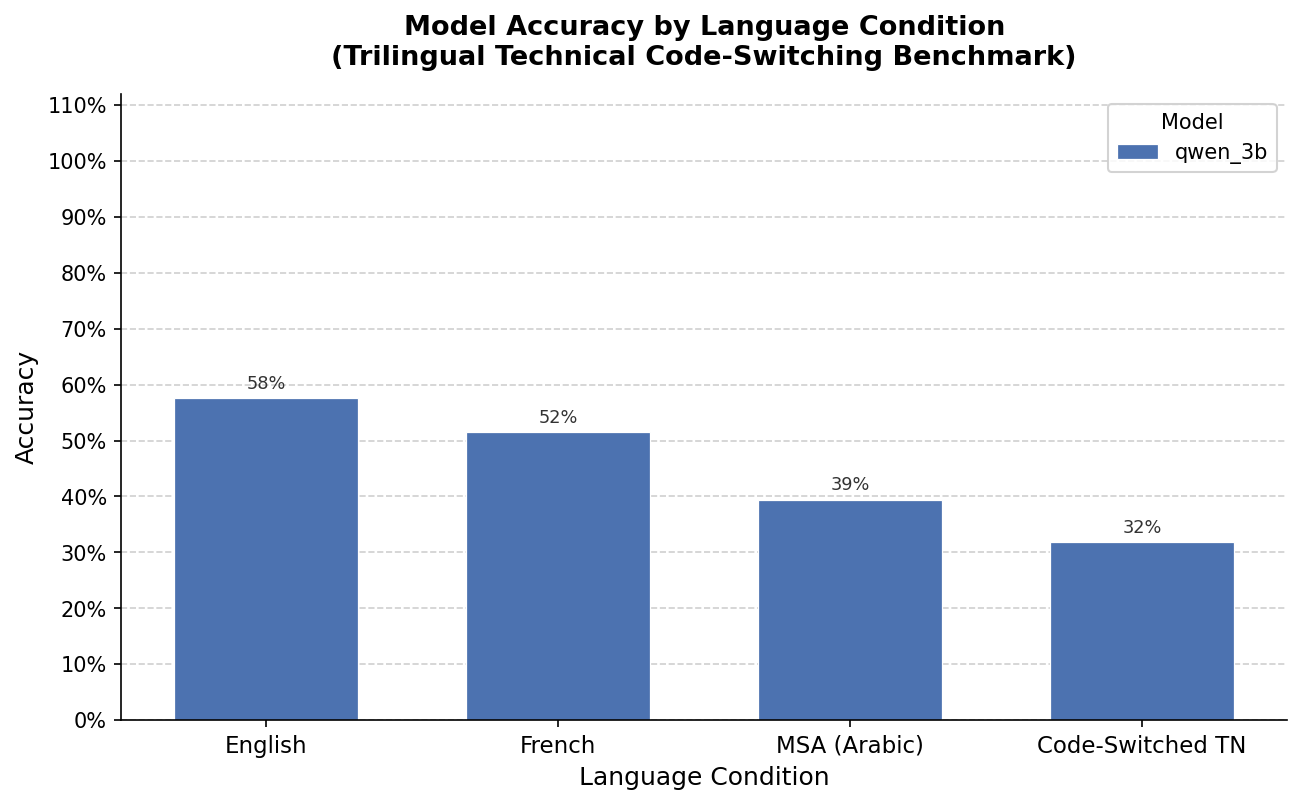

In [7]:
from IPython.display import Image, display
display(Image(filename='results/accuracy_by_condition.png'))

## 4. Domain analysis and uncertainty

In [8]:
auto = scored[scored.score != 'needs_manual_review'].copy()
auto['correct'] = (auto.score == 'correct').astype(int)
domain_table = auto.groupby(['domain', 'condition']).correct.agg(['mean', 'sum', 'count']).reset_index()
domain_table = domain_table.rename(columns={'mean': 'accuracy', 'sum': 'correct', 'count': 'n'})
display(domain_table.style.format({'accuracy': '{:.1%}'}))
def bootstrap_ci(values, n_boot=2000, seed=7):
    import numpy as np
    rng = np.random.default_rng(seed)
    values = np.asarray(values, dtype=float)
    if len(values) == 0: return (float('nan'), float('nan'))
    estimates = [rng.choice(values, len(values), replace=True).mean() for _ in range(n_boot)]
    return tuple(np.quantile(estimates, [0.025, 0.975]))
ci_rows = []
for (model, condition), group in auto.groupby(['model', 'condition']):
    lo, hi = bootstrap_ci(group.correct)
    ci_rows.append({'model': model, 'condition': condition, 'n': len(group), 'low': lo, 'high': hi})
display(pd.DataFrame(ci_rows).style.format({'low': '{:.1%}', 'high': '{:.1%}'}))

,domain,condition,accuracy,correct,n
0,algorithms,code_switched_tn,33.3%,4,12
1,algorithms,english,100.0%,12,12
2,algorithms,french,91.7%,11,12
3,algorithms,msa,41.7%,5,12
4,circuits,code_switched_tn,16.7%,2,12
5,circuits,english,25.0%,3,12
6,circuits,french,16.7%,2,12
7,circuits,msa,16.7%,2,12
8,debugging,code_switched_tn,20.0%,2,10
9,debugging,english,60.0%,6,10


,model,condition,n,low,high
0,qwen_3b,code_switched_tn,66,21.2%,43.9%
1,qwen_3b,english,66,45.5%,69.7%
2,qwen_3b,french,66,39.4%,63.6%
3,qwen_3b,msa,66,28.8%,51.5%


## 6. Limitations

The real limitation is that the benchmark currently uses hand-written, parallel prompts rather than naturally collected Tunisian technical conversations, so it may measure translation quality and wording differences instead of genuine code-switching failure. Because the language conditions are not yet controlled with matched minimal pairs and human validation, even a lower code-switched score cannot prove that code switching itself caused the model’s error.

In [10]:
!python scripts/export_artifacts.py
from pathlib import Path
for path in sorted(Path('results').glob('*')):
    print(path)

Exported 66 dataset rows to /content/Trilingual-Technical-Code-Switching/dataset/evaluation.jsonl
Wrote metadata templates to /content/Trilingual-Technical-Code-Switching/metadata
results/accuracy_by_condition.png
results/final_raw_outputs.csv
results/manual_review_queue.csv
results/run_metadata.json
results/scored_results.csv
results/summary.csv
